# Notebook 02 - Spectral Processing and Outlier Detection

Processes NIR and MIR using reference parameters, applies smoothing and SNV, supports optional continuum removal, and performs PCA-based outlier detection (Hotelling T2 + Q).

 ## Quick Start: Setting up the environment

1. Ensure Notebook 01 has completed successfully and that `01_input_qc.json` exists in `Outputs/pipeline/`.
2. Place your input CSV files inside `Data/`.
3. Edit the User Configuration variables if needed: `NIR_FILENAME`, `MIR_FILENAME`, and `OUTPUT_SUBFOLDER`.
4. Run all cells in order.
5. Confirm outputs in `Outputs/pipeline/`: `02_nir_clean.csv`, `02_mir_clean.csv`, `02_nir_outliers.csv`, and `02_mir_outliers.csv`.
6. Review `02_processing_metadata.json` and `02_user_report.txt` for preprocessing metadata and an execution summary.
7. If a validation fails, follow the error message and inspect the generated `02_expected_ranges_inferred.csv` before retrying.


In [1]:
import importlib.util
import sys

RUNTIME_PACKAGES = {
    'numpy': 'numpy',
    'pandas': 'pandas',
    'matplotlib': 'matplotlib',
    'pyyaml': 'yaml',
    'scipy': 'scipy',
    'scikit-learn': 'sklearn',
}

OPTIONAL_PACKAGES = {
    'ipywidgets': 'ipywidgets',
}

missing_packages = [
    pkg_name
    for pkg_name, module_name in RUNTIME_PACKAGES.items()
    if importlib.util.find_spec(module_name) is None
]
if missing_packages:
    print('Missing dependencies detected:')
    for package_name in missing_packages:
        print(f'  - {package_name}')
    raise RuntimeError(
        'This notebook cannot continue because required packages are missing. '
        'Run launch_pipeline_vscode.bat from the repository root, reopen VS Code, and run this notebook again.'
    )

missing_optional = [
    pkg_name
    for pkg_name, module_name in OPTIONAL_PACKAGES.items()
    if importlib.util.find_spec(module_name) is None
]
if missing_optional:
    print('Optional dependencies not found (advanced UI features will fall back to simple mode):')
    for package_name in missing_optional:
        print(f'  - {package_name}')

if '.venv' not in str(sys.executable).lower():
    print('Warning: active interpreter is not .venv. For non-technical users, run launch_pipeline_vscode.bat and reopen VS Code.')
else:
    print('Environment check passed: .venv interpreter detected and required packages are available.')

Environment check passed: .venv interpreter detected and required packages are available.


## Theoretical Framework

This notebook implements the standard **spectral preprocessing chain** for soil spectroscopy. The operation order is deliberate and technically justified:

```
Raw data
    -> Technical trimming
    -> Smoothing (Savitzky-Golay)
    -> Splice correction
    -> Normalization (SNV)
    -> Outlier detection (PCA + Hotelling T2 + Q)
    -> Partition: clean spectra / outlier table
```

Each step and generated file has a specific role in the workflow. Parameters are loaded from `Reference/parameters.yaml` to guarantee reproducibility (**Poppiel et al., 2022**).

**Sequence guard:** this notebook requires `01_input_qc.json` before execution, ensuring Notebook 01 QC was completed.

In [2]:
import yaml
from pathlib import Path
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use inline backend to avoid widget-communication deadlocks during kernel restart.
try:
    from IPython import get_ipython
    _ipy = get_ipython()
    if _ipy is not None:
        _ipy.run_line_magic('matplotlib', 'inline')
        print('Matplotlib backend set to inline for stable execution.')
except Exception as backend_error:
    print(f'Warning: could not explicitly set matplotlib inline backend: {backend_error}')

ROOT = Path.cwd().resolve().parent if Path.cwd().name.lower() == 'notebooks' else Path.cwd().resolve()
if str(ROOT) not in sys.path:
    sys.path.append(str(ROOT))

REFERENCE_DIR = ROOT / 'Reference'
DATA_DIR = ROOT / 'Data'
OUTPUT_SUBFOLDER = 'pipeline'
UPSTREAM_SUBFOLDER = OUTPUT_SUBFOLDER
NIR_FILENAME = ''
MIR_FILENAME = ''
AUTO_DETECT_INPUT_FILES = True
USE_CONTINUUM_REMOVAL = True
UNIQUE_RUN_FOLDER = False
OUTPUT_DIR = ROOT / 'Outputs' / OUTPUT_SUBFOLDER
FIG_DIR = OUTPUT_DIR / 'Figures'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

from spectral_pipeline_utils import (
    infer_domain_rules_from_wavelengths,
    expected_ranges_frame,
    read_csv_auto,
    get_spectral_columns,
    validate_axis,
    fill_nans_matrix,
    savgol_safe,
    detect_splice_points,
    apply_splicing_correction,
    detect_outliers_pca,
    continuum_remove_matrix,
    rowwise_snv,
    run_stamp,
    write_json,
 )

PARAMS_PATH = REFERENCE_DIR / 'parameters.yaml'
EXPECTED_RANGES_INFERRED_PATH = OUTPUT_DIR / '02_expected_ranges_inferred.csv'


def pick_input_file(preferred_name: str, keyword: str) -> Path:
    if preferred_name:
        preferred = DATA_DIR / preferred_name
        if preferred.exists():
            return preferred
        if not AUTO_DETECT_INPUT_FILES:
            return preferred
        print(f"Configured {keyword.upper()} file not found: {preferred.name}. Trying auto-detection in Data/.")

    candidates = sorted(DATA_DIR.glob('*.csv'))
    if not candidates:
        raise FileNotFoundError(f'No CSV files were found in {DATA_DIR}. Add one {keyword} file and rerun.')

    keyword_map = {
        'nir': ('nir', 'vnir', 'visnir', 'vis', 'spectro'),
        'mir': ('mir', 'ftir', 'drift', 'mid'),
    }.get(keyword.lower(), (keyword.lower(),))
    matches = [path for path in candidates if any(token in path.name.lower() for token in keyword_map)]

    if len(matches) == 1:
        print(f"Auto-detected {keyword.upper()} input file: {matches[0].name}")
        return matches[0]
    if len(matches) > 1:
        print(f"Multiple {keyword.upper()} candidates found. Using first alphabetical match: {matches[0].name}")
        return matches[0]
    if len(candidates) == 1:
        print(f"Only one CSV found in Data/. Using it as {keyword.upper()} input: {candidates[0].name}")
        return candidates[0]

    raise FileNotFoundError(
        f'Could not auto-detect a unique {keyword} input file in {DATA_DIR}. '
        'Please leave the filename blank only if the file name contains a clear domain keyword, or set the filename explicitly in the user configuration.'
    )


NIR_PATH = pick_input_file(NIR_FILENAME, 'nir')
MIR_PATH = pick_input_file(MIR_FILENAME, 'mir')

required_paths = [
    ('parameters', PARAMS_PATH),
    ('nir_input', NIR_PATH),
    ('mir_input', MIR_PATH),
]
missing = [f'{label}: {path}' for label, path in required_paths if not path.exists()]
if missing:
    raise FileNotFoundError(
        'Missing required files. Place your CSV inputs in Data/ or update the User Configuration block:\n' + '\n'.join(missing)
    )

REQUIRED_UPSTREAM = ROOT / 'Outputs' / UPSTREAM_SUBFOLDER / '01_input_qc.json'
if not REQUIRED_UPSTREAM.exists():
    raise FileNotFoundError(
        f'Stage 01 artifact not found: {REQUIRED_UPSTREAM}. '
        'Please open Stage 01 notebook and run all cells first, then return to Stage 02.'
    )

with PARAMS_PATH.open('r', encoding='utf-8') as f:
    params = yaml.safe_load(f) or {}

smoothing_cfg = params.get('preprocessing', {}).get('smoothing', {})
outlier_cfg = params.get('outlier_detection', {})
splice_cfg = params.get('preprocessing', {}).get('splice', {})
trim_cfg = params.get('preprocessing', {}).get('technical_trim', {})

NIR_TRIM_ENABLED = bool(trim_cfg.get('enabled', True))
NIR_TRIM_MIN_NM = float(trim_cfg.get('nir_min_nm', 450.0))

# Lightweight user controls
TRIM_UI_MODE = 'widget'  # options: 'simple', 'widget'
NIR_TRIM_ENABLED_USER = NIR_TRIM_ENABLED
NIR_TRIM_MIN_NM_USER = NIR_TRIM_MIN_NM

# Optional MIR trim controls (disabled by default)
MIR_TRIM_UI_ENABLED = False
MIR_TRIM_ENABLED_USER = False
MIR_TRIM_MIN_CM1_USER = 650.0

# Representative sampling controls (before trim)
REP_SAMPLE_BINS = 12
REP_SAMPLE_PER_BIN = 12
REP_SAMPLE_MAX = 144
REP_SAMPLE_SEED = 42

# Plotting controls
PLOT_REPRESENTATIVE_SAMPLE = True
PLOT_MEAN_STD_AFTER_TRIM_DECISION = True

# Widget and cache objects are created once and reused across reruns.
trim_enabled_widget = None
trim_min_widget = None
trim_apply_button = None
trim_plot_output = None
trim_controls_box = None
trim_ui_display_handle = None
REP_SAMPLE_CACHE = {}
TRIM_PREVIEW_CACHE = {}


def _effective_trim_controls() -> tuple[bool, float]:
    if TRIM_UI_MODE == 'widget' and 'trim_enabled_widget' in globals() and 'trim_min_widget' in globals():
        return bool(trim_enabled_widget.value), float(trim_min_widget.value)
    return bool(NIR_TRIM_ENABLED_USER), float(NIR_TRIM_MIN_NM_USER)


def representative_spectral_sample_indices(
    X: np.ndarray,
    n_bins: int = 12,
    per_bin: int = 12,
    max_total: int = 144,
    random_seed: int = 42,
 ) -> np.ndarray:
    """Lightweight stratified sample by row-mean intensity quantiles."""
    Xf = fill_nans_matrix(X.copy())
    n_samples = Xf.shape[0]
    if n_samples <= max_total:
        return np.arange(n_samples, dtype=int)

    score = np.nanmean(Xf, axis=1)
    rng = np.random.default_rng(random_seed)
    edges = np.quantile(score, np.linspace(0.0, 1.0, n_bins + 1))
    selected = []

    for i in range(n_bins):
        if i < n_bins - 1:
            in_bin = np.where((score >= edges[i]) & (score < edges[i + 1]))[0]
        else:
            in_bin = np.where((score >= edges[i]) & (score <= edges[i + 1]))[0]
        if in_bin.size == 0:
            continue
        take = min(per_bin, in_bin.size)
        chosen = rng.choice(in_bin, size=take, replace=False)
        selected.extend(chosen.tolist())

    selected = np.array(sorted(set(selected)), dtype=int)
    if selected.size == 0:
        selected = rng.choice(np.arange(n_samples), size=max_total, replace=False)
        selected = np.array(sorted(selected), dtype=int)
    elif selected.size > max_total:
        selected = rng.choice(selected, size=max_total, replace=False)
        selected = np.array(sorted(selected), dtype=int)

    return selected


def get_representative_indices_cached(
    X: np.ndarray,
    cache_key: str,
    n_bins: int = 12,
    per_bin: int = 12,
    max_total: int = 144,
    random_seed: int = 42,
 ) -> np.ndarray:
    key = (cache_key, int(X.shape[0]), int(X.shape[1]), int(n_bins), int(per_bin), int(max_total), int(random_seed))
    if key not in REP_SAMPLE_CACHE:
        REP_SAMPLE_CACHE[key] = representative_spectral_sample_indices(
            X,
            n_bins=int(n_bins),
            per_bin=int(per_bin),
            max_total=int(max_total),
            random_seed=int(random_seed),
        )
    return REP_SAMPLE_CACHE[key]


def render_trim_preview(trim_enabled: bool, trim_min_nm: float):
    if 'X_nir_raw_full' not in globals() or 'wavelengths_nir' not in globals():
        raise RuntimeError('Step 1 must be executed before previewing trim effects.')

    trim_enabled_local = bool(trim_enabled)
    trim_min_local = float(trim_min_nm)

    cache_key = (
        trim_enabled_local,
        round(trim_min_local, 4),
        int(X_nir_raw_full.shape[0]),
        int(X_nir_raw_full.shape[1]),
    )

    if cache_key in TRIM_PREVIEW_CACHE:
        payload = TRIM_PREVIEW_CACHE[cache_key]
    else:
        X_nir_preview = X_nir_raw_full
        wl_nir_preview = wavelengths_nir
        note = f"No trim: keeping full wavelength range ({wavelengths_nir.min():.0f}-{wavelengths_nir.max():.0f} nm)"

        if trim_enabled_local:
            trim_mask = wavelengths_nir >= trim_min_local
            n_kept = int(np.sum(trim_mask))
            if n_kept < 10:
                trim_enabled_local = False
                note = f"Warning: trim would leave only {n_kept} wavelengths. Showing untrimmed data."
            else:
                wl_nir_preview = wavelengths_nir[trim_mask]
                X_nir_preview = X_nir_raw_full[:, trim_mask]
                note = f"Trim applied: keeping {n_kept} wavelengths from {trim_min_local:.1f} nm onward"

        payload = {
            'trim_enabled_effective': trim_enabled_local,
            'trim_min_nm_effective': trim_min_local,
            'wl_nir_preview': wl_nir_preview,
            'mean_nir': np.nanmean(X_nir_preview, axis=0),
            'std_nir': np.nanstd(X_nir_preview, axis=0),
            'note': note,
        }
        TRIM_PREVIEW_CACHE[cache_key] = payload

    print(f"Trim enabled: {payload['trim_enabled_effective']}")
    print(f"Trim threshold: {payload['trim_min_nm_effective']:.1f} nm")
    print(payload['note'])
    print('')

    if not PLOT_MEAN_STD_AFTER_TRIM_DECISION:
        print('Final mean +/- SD plot is disabled by configuration (PLOT_MEAN_STD_AFTER_TRIM_DECISION=False).')
        return

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(payload['wl_nir_preview'], payload['mean_nir'], color='tab:orange', linewidth=2.5, label='Mean')
    ax.fill_between(
        payload['wl_nir_preview'],
        payload['mean_nir'] - payload['std_nir'],
        payload['mean_nir'] + payload['std_nir'],
        color='tab:orange',
        alpha=0.25,
        label='Mean +/- 1 SD'
)

    if payload['trim_enabled_effective']:
        ax.axvline(payload['trim_min_nm_effective'], color='tab:red', ls='--', lw=2, alpha=0.8, label='Trim cutoff')
        title_str = f"NIR Mean +/- SD with Technical Trim (threshold = {payload['trim_min_nm_effective']:.1f} nm)"
    else:
        title_str = 'NIR Mean +/- SD (full range, no trim)'

    ax.set_title(title_str, fontsize=13)
    ax.set_xlabel('Wavelength (nm)', fontsize=11)
    ax.set_ylabel('Reflectance', fontsize=11)
    ax.grid(alpha=0.2)
    ax.legend(loc='best', fontsize=10)
    fig.tight_layout()
    plt.show()


print('User configuration loaded successfully:')
print(f'  NIR input: {NIR_PATH}')
print(f'  MIR input: {MIR_PATH}')
print(f'  Output folder: {OUTPUT_DIR}')
print(f'  Stage 01 artifact: {REQUIRED_UPSTREAM}')
print(f'  Technical trim enabled (default): {NIR_TRIM_ENABLED}')
print(f'  Technical trim threshold (default): {NIR_TRIM_MIN_NM:.1f} nm')
if USE_CONTINUUM_REMOVAL:
    print('  Spectral Baseline Correction (Continuum Removal): Active [Recommended]')
print('')
print('System is ready. Proceed to the next steps for Technical Trim decisions.\n')
print('Workflow sequence:')
print('  1. View representative raw sample (Step 1)')
print('  2. Set trim ON/OFF and threshold in nm (Step 2)')
print('  3. Click "Update Settings" and run Step 3 to render one final mean +/- SD preview')
print('  4. Run full processing pipeline')
print('')
print('  Spectral ranges will be inferred from data and saved to 02_expected_ranges_inferred.csv')

Matplotlib backend set to inline for stable execution.
Auto-detected NIR input file: Atributos_VIS.NIR_SP.csv
Auto-detected MIR input file: Atributos_MIR_SP.csv
User configuration loaded successfully:
  NIR input: C:\Users\DANIEL\Desktop\GeoCiS_Spectroscopy\Data\Atributos_VIS.NIR_SP.csv
  MIR input: C:\Users\DANIEL\Desktop\GeoCiS_Spectroscopy\Data\Atributos_MIR_SP.csv
  Output folder: C:\Users\DANIEL\Desktop\GeoCiS_Spectroscopy\Outputs\pipeline
  Stage 01 artifact: C:\Users\DANIEL\Desktop\GeoCiS_Spectroscopy\Outputs\pipeline\01_input_qc.json
  Technical trim enabled (default): True
  Technical trim threshold (default): 450.0 nm
  Spectral Baseline Correction (Continuum Removal): Active [Recommended]

System is ready. Proceed to the next steps for Technical Trim decisions.

Workflow sequence:
  1. View representative raw sample (Step 1)
  2. Set trim ON/OFF and threshold in nm (Step 2)
  3. Click "Update Settings" and run Step 3 to render one final mean +/- SD preview
  4. Run full proc

## Block 1 - Preprocessing Pipeline (`process_domain`)

### 1. User-Controlled Technical Trim (first decision)
Technical trim is defined by the user (Step 2) and applied at the beginning of Stage 02. For NIR, this usually removes low-energy UV-edge wavelengths (commonly below about 450 nm) that can inflate variance and destabilize outlier diagnostics.

### 2. Savitzky-Golay Transformation Family (SG0, SG1, SG2)
After trim, the pipeline applies **Savitzky-Golay** (`window_length=11`, `polyorder=2` in `parameters.yaml`) in three forms:
- **SG0**: smoothed spectrum (noise reduction while preserving band shape)
- **SG1**: first derivative (slope-sensitive features)
- **SG2**: second derivative (curvature and absorption-center sharpening)

> **Dematte et al. (2022)** discuss why preserving absorption-feature geometry is critical in soil spectroscopy and why local-polynomial smoothing is preferred over naive averaging for this purpose.

In this pipeline, SG0 is used in the main preprocessing chain, while SG1/SG2 are computed and registered for traceability and exploratory interpretation.

### 3. Splice Correction and Optional Continuum Removal
For NIR, potential detector splice regions are corrected using configured or auto-detected splice points. Optionally, continuum removal can be applied to normalize envelope effects before sample-wise scaling.

### 4. SNV Normalization and PCA-Based Outlier Detection
Processed spectra are standardized by **SNV** and then evaluated with PCA diagnostics:
- **Hotelling T2** (score-space extremeness)
- **Q residuals** (reconstruction error)

Samples exceeding configured confidence thresholds are flagged in `02_{domain}_outliers.csv`, while outlier-free spectra are exported to `02_{domain}_clean.csv` for downstream notebooks.

## Step 1: View a Representative Raw Sample

Before any preprocessing decision, first inspect the raw spectra. This step shows a representative statistical sample so you can see baseline behavior, noise, and possible artifacts in the original measurements.

### Why this comes first

- Data quality check: identifies noisy regions, abrupt jumps, and unusual shapes before any transformation.
- Scientific transparency: keeps the decision process traceable from raw data to processed outputs.
- Better trim decision: helps define whether a technical cutoff (for example, around 450 nm in NIR) is justified for your dataset.

The sample is selected with stratified random sampling across spectral intensity quantiles, so the visualization is informative without plotting every spectrum. This follows the same quality-first logic recommended by Dematte et al. (2022) for early spectral screening.

Loaded 6120 NIR spectra with 2151 wavelengths
Loaded 616 MIR spectra with 681 wavelengths



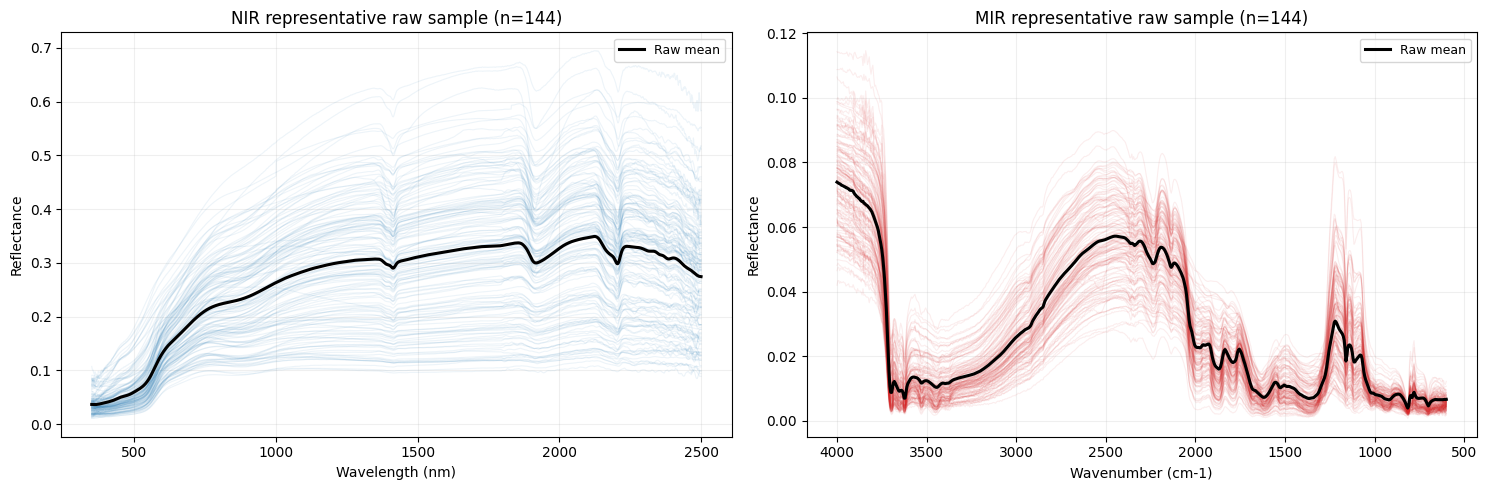

Displayed representative NIR sample: 144 of 6120 spectra
Displayed representative MIR sample: 144 of 616 spectra

Observation guide: identify wavelength regions with high noise, abrupt jumps, or unstable signal before setting trim in Step 2.


In [3]:
# Load raw NIR and MIR data and preview representative statistical sample

# Load NIR
df_nir_raw, _ = read_csv_auto(NIR_PATH)
metadata_cols_nir, spectral_cols_nir, wavelengths_nir = get_spectral_columns(df_nir_raw)
X_nir_raw_full = df_nir_raw[spectral_cols_nir].apply(pd.to_numeric, errors='coerce').to_numpy(dtype=float)
valid_rows_nir = np.isfinite(X_nir_raw_full).any(axis=1)
X_nir_raw_full = fill_nans_matrix(X_nir_raw_full[valid_rows_nir])

# Load MIR
df_mir_raw, _ = read_csv_auto(MIR_PATH)
metadata_cols_mir, spectral_cols_mir, wavelengths_mir = get_spectral_columns(df_mir_raw)
X_mir_raw_full = df_mir_raw[spectral_cols_mir].apply(pd.to_numeric, errors='coerce').to_numpy(dtype=float)
valid_rows_mir = np.isfinite(X_mir_raw_full).any(axis=1)
X_mir_raw_full = fill_nans_matrix(X_mir_raw_full[valid_rows_mir])

print(f"Loaded {X_nir_raw_full.shape[0]} NIR spectra with {X_nir_raw_full.shape[1]} wavelengths")
print(f"Loaded {X_mir_raw_full.shape[0]} MIR spectra with {X_mir_raw_full.shape[1]} wavelengths")
print('')

if PLOT_REPRESENTATIVE_SAMPLE:
    rep_idx_nir = get_representative_indices_cached(
        X_nir_raw_full,
        cache_key='nir_raw',
        n_bins=int(REP_SAMPLE_BINS),
        per_bin=int(REP_SAMPLE_PER_BIN),
        max_total=int(REP_SAMPLE_MAX),
        random_seed=int(REP_SAMPLE_SEED),
    )
    rep_idx_mir = get_representative_indices_cached(
        X_mir_raw_full,
        cache_key='mir_raw',
        n_bins=int(REP_SAMPLE_BINS),
        per_bin=int(REP_SAMPLE_PER_BIN),
        max_total=int(REP_SAMPLE_MAX),
        random_seed=int(REP_SAMPLE_SEED),
    )

    X_rep_nir = X_nir_raw_full[rep_idx_nir]
    X_rep_mir = X_mir_raw_full[rep_idx_mir]

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    axes[0].plot(wavelengths_nir, X_rep_nir.T, color='tab:blue', alpha=0.08, linewidth=0.8)
    axes[0].plot(wavelengths_nir, np.nanmean(X_nir_raw_full, axis=0), color='black', linewidth=2.2, label='Raw mean')
    axes[0].set_title(f'NIR representative raw sample (n={X_rep_nir.shape[0]})')
    axes[0].set_xlabel('Wavelength (nm)')
    axes[0].set_ylabel('Reflectance')
    axes[0].grid(alpha=0.2)
    axes[0].legend(loc='best', fontsize=9)

    axes[1].plot(wavelengths_mir, X_rep_mir.T, color='tab:red', alpha=0.08, linewidth=0.8)
    axes[1].plot(wavelengths_mir, np.nanmean(X_mir_raw_full, axis=0), color='black', linewidth=2.2, label='Raw mean')
    axes[1].set_title(f'MIR representative raw sample (n={X_rep_mir.shape[0]})')
    axes[1].set_xlabel('Wavenumber (cm-1)')
    axes[1].set_ylabel('Reflectance')
    axes[1].invert_xaxis()
    axes[1].grid(alpha=0.2)
    axes[1].legend(loc='best', fontsize=9)

    fig.tight_layout()
    plt.show()

    print(f"Displayed representative NIR sample: {X_rep_nir.shape[0]} of {X_nir_raw_full.shape[0]} spectra")
    print(f"Displayed representative MIR sample: {X_rep_mir.shape[0]} of {X_mir_raw_full.shape[0]} spectra")

print('')
print('Observation guide: identify wavelength regions with high noise, abrupt jumps, or unstable signal before setting trim in Step 2.')

## Step 2: Set Technical Trim Parameters

Use these controls to define the NIR technical-trim configuration that will be applied in Stage 02.

### How to use the controls

- ON/OFF toggle: activates or deactivates NIR technical trim.
- Threshold (nm): sets the minimum wavelength retained when trim is ON.
- Click **Update Settings**: stores the selected values for the next preview and processing steps.

In NIR workflows, technical trim is commonly used to reduce low-energy sensor noise (often below approximately 450 nm), which can otherwise increase variance and bias outlier diagnostics.

Default values are loaded from `Reference/parameters.yaml`, but they can be adjusted here based on the raw-signal inspection from Step 1.

The update is intentionally explicit (button-based) to avoid repeated redraw events and preserve stable notebook behavior.

In [4]:
# Create and display interactive trim controls

if TRIM_UI_MODE == 'widget':
    try:
        widgets = __import__('ipywidgets')
        from IPython.display import display, clear_output
        import time

        clear_output(wait=True)
        print("Creating interactive trim controls...")

        # NIR controls
        if trim_enabled_widget is None:
            trim_enabled_widget = widgets.Checkbox(
                value=bool(NIR_TRIM_ENABLED_USER),
                description='Enable NIR Technical Trim'
            )
        if trim_min_widget is None:
            trim_min_widget = widgets.FloatText(
                value=float(NIR_TRIM_MIN_NM_USER),
                description='NIR trim threshold (nm)',
                step=1.0,
                min=300.0,
                max=2500.0
            )

        # MIR controls (disabled by default, for future use)
        mir_trim_enabled_widget = widgets.Checkbox(
            value=bool(MIR_TRIM_ENABLED_USER),
            description='Enable MIR Technical Trim',
            disabled=not bool(MIR_TRIM_UI_ENABLED)
        )
        mir_trim_min_widget = widgets.FloatText(
            value=float(MIR_TRIM_MIN_CM1_USER),
            description='MIR trim threshold (cm-1)',
            step=1.0,
            min=400.0,
            max=4000.0,
            disabled=not bool(MIR_TRIM_UI_ENABLED)
        )

        # Recreate button every run to avoid stale frontend handlers.
        if trim_apply_button is not None:
            try:
                trim_apply_button.close()
            except Exception:
                pass

        trim_apply_button = widgets.Button(
            description='Update Settings',
            button_style='primary',
            icon='check'
        )

        # Global state for dedup and explicit apply event.
        if '_trim_apply_state' not in globals() or not isinstance(_trim_apply_state, dict):
            _trim_apply_state = {'last_ts': 0.0, 'apply_count': 0}

        def _on_trim_apply_clicked(_):
            global _trim_apply_state
            now = time.perf_counter()
            if (now - float(_trim_apply_state.get('last_ts', 0.0))) < 1.0:
                return
            _trim_apply_state['last_ts'] = now

            # Sync NIR values to global user vars
            globals()['NIR_TRIM_ENABLED_USER'] = bool(trim_enabled_widget.value)
            globals()['NIR_TRIM_MIN_NM_USER'] = float(trim_min_widget.value)

            # Sync MIR values (future use)
            globals()['MIR_TRIM_ENABLED_USER'] = bool(mir_trim_enabled_widget.value)
            globals()['MIR_TRIM_MIN_CM1_USER'] = float(mir_trim_min_widget.value)

            # Step 3 reads this state and renders exactly once per cell run.
            _trim_apply_state['apply_count'] = int(_trim_apply_state.get('apply_count', 0)) + 1

        trim_apply_button.on_click(_on_trim_apply_clicked)

        trim_controls_box = widgets.VBox([
            widgets.HTML("<b>Step 2: Trim controls</b>"),
            widgets.HTML("<b>NIR (active)</b>"),
            trim_enabled_widget,
            trim_min_widget,
            widgets.HTML("<b>MIR (optional, currently disabled)</b>"),
            mir_trim_enabled_widget,
            mir_trim_min_widget,
            trim_apply_button,
        ])

        display(trim_controls_box)
        print("Controls are active. Click 'Update Settings' and then run Step 3 to render one preview.")

    except Exception as e:
        print('ipywidgets not available or UI cannot be rendered. Falling back to simple mode.')
        print(f'Error: {e}')
        TRIM_UI_MODE = 'simple'
        print('Simple mode enabled. Update NIR_TRIM_ENABLED_USER and NIR_TRIM_MIN_NM_USER in the User Configuration section, then run Step 3.')
else:
    print('Simple mode (no interactive widgets).')
    print(f'Current settings: trim_enabled={NIR_TRIM_ENABLED_USER}, trim_min_nm={NIR_TRIM_MIN_NM_USER}')
    print('To change settings, update NIR_TRIM_ENABLED_USER and NIR_TRIM_MIN_NM_USER in the User Configuration section.')

print('')
print('Next step: in widget mode click Update Settings and run Step 3; in simple mode run Step 3 to visualize mean +/- SD.')

Creating interactive trim controls...


Controls are active. Click 'Update Settings' and then run Step 3 to render one preview.

Next step: in widget mode click Update Settings and run Step 3; in simple mode run Step 3 to visualize mean +/- SD.


## Step 3: Render Final Spectrum Preview (Mean +/- SD)

This step generates a single preview of the final raw-spectrum summary using the currently stored trim parameters.

### Interpretation

- Mean spectrum: central tendency across samples.
- Mean +/- 1 SD envelope: dispersion around the mean.
- Trim cutoff line (when enabled): exact wavelength boundary applied to NIR.

In **widget mode**, first click **Update Settings** in Step 2, then run this cell to render one preview.
In **simple mode**, update `NIR_TRIM_ENABLED_USER` and `NIR_TRIM_MIN_NM_USER`, then run this cell.

This separation is intentional: Step 2 is parameter registration, while Step 3 is controlled visualization. The design improves reproducibility and avoids duplicate plot rendering events.

Widget mode is active.
Current trim settings -> enabled=False, threshold=450.0 nm
Rendering one preview for current settings...
Trim enabled: False
Trim threshold: 450.0 nm
No trim: keeping full wavelength range (350-2500 nm)



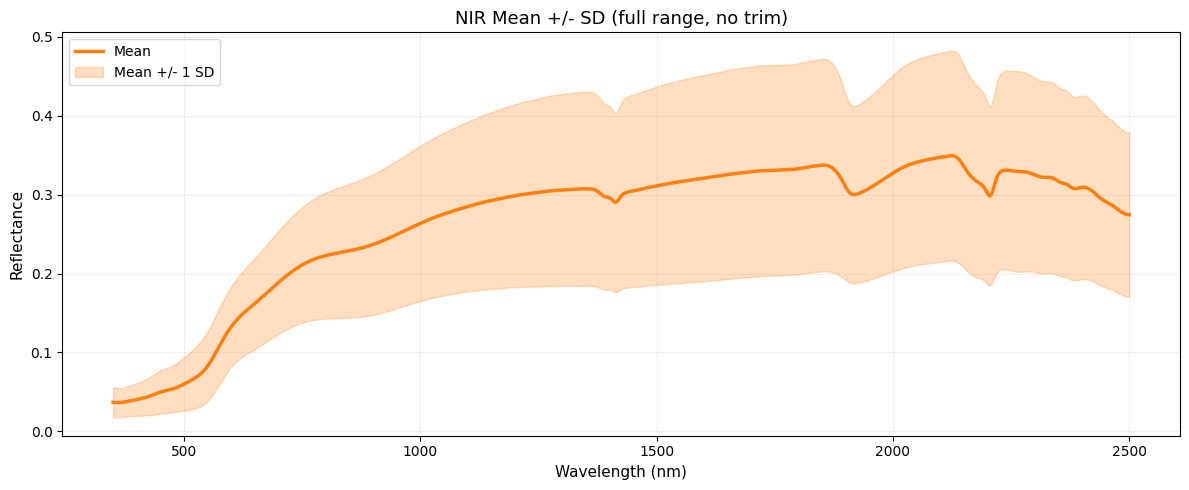

Ready to process. Run the full processing step to execute Stage 02 with this trim decision.


In [5]:
# Plot mean +/- SD spectrum reflecting user's trim choice

trim_enabled_effective, trim_min_nm_effective = _effective_trim_controls()

if TRIM_UI_MODE == 'widget':
    print('Widget mode is active.')
    print(f'Current trim settings -> enabled={trim_enabled_effective}, threshold={trim_min_nm_effective:.1f} nm')
    print('Rendering one preview for current settings...')
else:
    print('Simple mode is active.')
    print(f'Current trim settings -> enabled={trim_enabled_effective}, threshold={trim_min_nm_effective:.1f} nm')

render_trim_preview(trim_enabled_effective, trim_min_nm_effective)
print('Ready to process. Run the full processing step to execute Stage 02 with this trim decision.')

In [6]:
inferred_rules_records = []


def process_domain(domain: str, input_path: Path):
    t0 = time.perf_counter()
    try:
        print(f"\n[Stage 02] Processing {domain.upper()} from {input_path.name}...")
        df_raw, enc = read_csv_auto(input_path)

        metadata_cols, spectral_cols, wavelengths = get_spectral_columns(df_raw)
        rules = infer_domain_rules_from_wavelengths(wavelengths, domain)
        inferred_rules_records.append(rules)
        obs_min, obs_max = validate_axis(wavelengths, rules, domain.upper())

        meta = df_raw[metadata_cols].copy()
        X_raw_full = df_raw[spectral_cols].apply(pd.to_numeric, errors='coerce').to_numpy(dtype=float)
        valid_rows = np.isfinite(X_raw_full).any(axis=1)
        meta = meta.loc[valid_rows].reset_index(drop=True)
        X_raw_full = fill_nans_matrix(X_raw_full[valid_rows])

        if X_raw_full.shape[0] == 0:
            raise ValueError(f"No valid spectral rows were found for domain '{domain}'.")

        # Representative sample preview is now shown in cell 8, not here.

        # User-controlled technical trim decision.
        trim_applied = False
        trim_min_nm_used = None
        trim_enabled_effective, trim_min_nm_effective = _effective_trim_controls()

        X = X_raw_full.copy()
        wl_used = wavelengths.copy()

        if domain == 'nir' and trim_enabled_effective:
            trim_mask = wavelengths >= float(trim_min_nm_effective)
            if int(np.sum(trim_mask)) < 10:
                raise ValueError(f'Technical trim left too few NIR bands: {int(np.sum(trim_mask))}')
            wl_used = wavelengths[trim_mask]
            X = X_raw_full[:, trim_mask]
            trim_applied = True
            trim_min_nm_used = float(trim_min_nm_effective)

        # Mean +/- SD preview is shown in Step 3.

        X_smooth, sg_w, sg_p = savgol_safe(
            X,
            window_length=int(smoothing_cfg.get('window_length', 11)),
            polyorder=int(smoothing_cfg.get('polyorder', 2)),
        )

        # SG1/SG2 derivatives are computed for provenance and interpretation.
        from scipy.signal import savgol_filter
        delta = float(np.nanmedian(np.abs(np.diff(wl_used)))) if wl_used.size > 1 else 1.0
        if not np.isfinite(delta) or delta <= 0.0:
            delta = 1.0
        if X.shape[1] >= int(sg_w):
            X_sg1 = savgol_filter(X, window_length=int(sg_w), polyorder=int(sg_p), deriv=1, delta=delta, axis=1, mode='interp')
            X_sg2 = savgol_filter(X, window_length=int(sg_w), polyorder=int(sg_p), deriv=2, delta=delta, axis=1, mode='interp')
        else:
            X_sg1 = np.full_like(X, np.nan)
            X_sg2 = np.full_like(X, np.nan)

        splice_points_used = []
        X_proc = X_smooth.copy()
        if domain == 'nir':
            sp = splice_cfg.get('nir_preset_points_nm', [])
            if not sp and bool(splice_cfg.get('detect_auto_if_empty', True)):
                max_auto_points = int(splice_cfg.get('max_auto_points', 2))
                min_gap_auto = float(splice_cfg.get('min_gap_auto', 80.0))
                sp = detect_splice_points(wl_used, np.nanmean(X_smooth, axis=0), max_points=max_auto_points, min_gap=min_gap_auto)
            X_proc, _ = apply_splicing_correction(X_smooth, wl_used, sp, float(splice_cfg.get('window_nm', 20.0)))
            splice_points_used = [float(v) for v in sp]

        if USE_CONTINUUM_REMOVAL:
            X_proc = continuum_remove_matrix(X_proc, wl_used)

        X_snv = rowwise_snv(X_proc)
        out = detect_outliers_pca(
            X_snv,
            n_components=int(outlier_cfg.get('n_components', 8)),
            alpha_t2=float(outlier_cfg.get('alpha_t2', 0.99)),
            alpha_q=float(outlier_cfg.get('alpha_q', 0.99)),
        )

        id_col = 'ID_Unico' if 'ID_Unico' in meta.columns else None
        sample_id = meta[id_col].reset_index(drop=True) if id_col else pd.Series(np.arange(1, out['n_total'] + 1))

        outlier_table = pd.DataFrame({
            'sample_id': sample_id,
            'T2': out['T2'],
            'T2_limit': out['T2_limit'],
            'Q': out['Q'],
            'Q_limit': out['Q_limit'],
            'outlier_T2': out['outlier_T2'],
            'outlier_Q': out['outlier_Q'],
            'outlier': out['outlier_mask'],
        })

        processed = pd.concat([
            meta.reset_index(drop=True),
            pd.DataFrame(X_proc, columns=[str(w) for w in wl_used])
        ], axis=1)
        clean = processed.loc[~out['outlier_mask']].copy()

        out_clean = OUTPUT_DIR / f'02_{domain}_clean.csv'
        out_outlier = OUTPUT_DIR / f'02_{domain}_outliers.csv'
        out_meta = OUTPUT_DIR / f'02_{domain}_processing_metadata.json'

        clean.to_csv(out_clean, index=False)
        outlier_table.to_csv(out_outlier, index=False)

        payload = {
            'domain': domain,
            'input_file': str(input_path),
            'encoding': enc,
            'rules': rules,
            'obs_min': obs_min,
            'obs_max': obs_max,
            'wl_min_used': float(np.nanmin(wl_used)),
            'wl_max_used': float(np.nanmax(wl_used)),
            'trim_applied': bool(trim_applied),
            'trim_min_nm_used': trim_min_nm_used,
            'trim_enabled_effective': bool(trim_enabled_effective),
            'output_clean': str(out_clean),
            'output_outliers': str(out_outlier),
            'n_clean': int(clean.shape[0]),
            'n_outliers': int(np.sum(out['outlier_mask'])),
            'n_total': int(out['n_total']),
            'splice_points_used': splice_points_used,
            'sg_window': int(sg_w),
            'sg_polyorder': int(sg_p),
            'savgol_pipeline': {
                'window_length': int(sg_w),
                'polyorder': int(sg_p),
                'sequence': ['SG0_smoothing', 'SG1_derivative', 'SG2_derivative'],
                'source': 'Reference/parameters.yaml::preprocessing.smoothing',
                'delta_used': float(delta),
                'sg1_computed': bool(np.isfinite(X_sg1).any()),
                'sg2_computed': bool(np.isfinite(X_sg2).any()),
            },
            'processing_seconds': float(time.perf_counter() - t0),
        }
        write_json(out_meta, run_stamp(f'02_{domain}_processing', payload))

        elapsed = time.perf_counter() - t0
        print(f"[Stage 02] {domain.upper()} done in {elapsed:.1f}s | outliers={int(np.sum(out['outlier_mask']))}/{int(out['n_total'])}")

        return {
            'domain': domain,
            'encoding': enc,
            'input_file': str(input_path),
            'rules': rules,
            'obs_min': obs_min,
            'obs_max': obs_max,
            'wl_min_used': float(np.nanmin(wl_used)),
            'wl_max_used': float(np.nanmax(wl_used)),
            'trim_applied': bool(trim_applied),
            'trim_min_nm_used': trim_min_nm_used,
            'trim_enabled_effective': bool(trim_enabled_effective),
            'wavelengths': wl_used,
            'processed': processed,
            'clean': clean,
            'outlier_table': outlier_table,
            'n_outliers': int(np.sum(out['outlier_mask'])),
            'n_total': int(out['n_total']),
            'splice_points_used': splice_points_used,
            'sg_window': int(sg_w),
            'sg_polyorder': int(sg_p),
            'sg1_mean': np.nanmean(X_sg1, axis=0),
            'sg2_mean': np.nanmean(X_sg2, axis=0),
            'mean_before': np.nanmean(X_smooth, axis=0),
            'mean_after': np.nanmean(X_proc, axis=0),
            'processing_seconds': float(elapsed),
        }
    except Exception as exc:
        raise RuntimeError(
            f"{domain.upper()} processing failed for file '{input_path}'. "
            f"Please validate the CSV format and the auto-detected input files. Details: {exc}"
        ) from exc


stage2_t0 = time.perf_counter()
nir_result = process_domain('nir', NIR_PATH)
mir_result = process_domain('mir', MIR_PATH)
expected_ranges_frame(inferred_rules_records).to_csv(EXPECTED_RANGES_INFERRED_PATH, index=False)
print(f"[Stage 02] Inferred spectral ranges saved to: {EXPECTED_RANGES_INFERRED_PATH}")
print(f"[Stage 02] Total processing time: {time.perf_counter() - stage2_t0:.1f}s")

print(f"NIR outliers: {nir_result['n_outliers']}/{nir_result['n_total']} | trim={nir_result['trim_applied']} ({nir_result['trim_min_nm_used']})")
print(f"MIR outliers: {mir_result['n_outliers']}/{mir_result['n_total']}")



[Stage 02] Processing NIR from Atributos_VIS.NIR_SP.csv...
[Stage 02] NIR done in 16.9s | outliers=485/6120

[Stage 02] Processing MIR from Atributos_MIR_SP.csv...
[Stage 02] MIR done in 0.8s | outliers=25/616
[Stage 02] Inferred spectral ranges saved to: C:\Users\DANIEL\Desktop\GeoCiS_Spectroscopy\Outputs\pipeline\02_expected_ranges_inferred.csv
[Stage 02] Total processing time: 17.8s
NIR outliers: 485/6120 | trim=False (None)
MIR outliers: 25/616


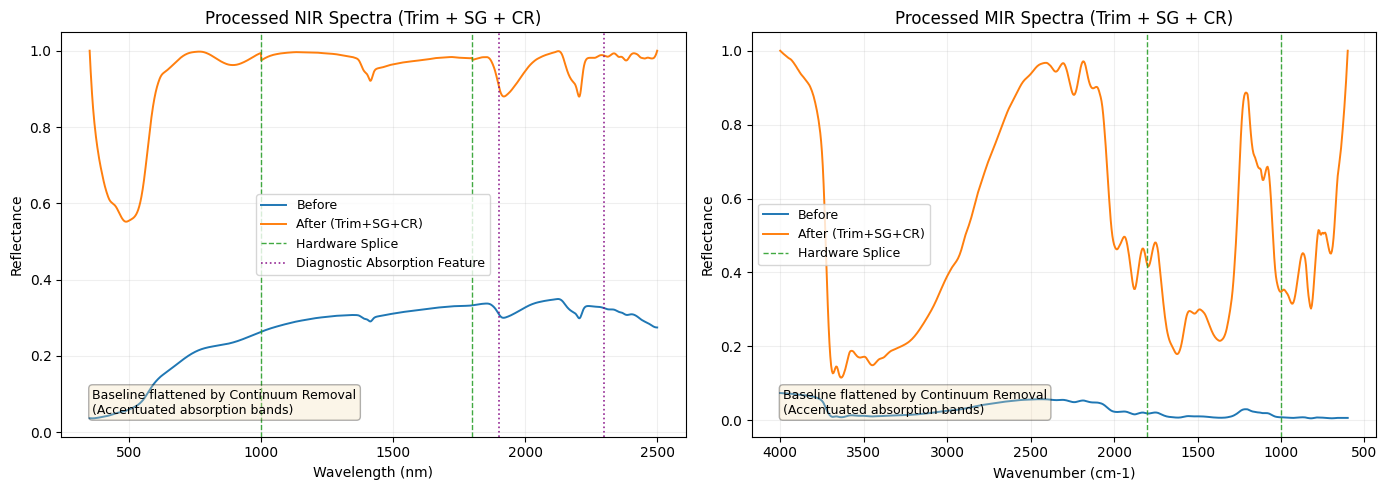

Stage 02 artifacts saved in: C:\Users\DANIEL\Desktop\GeoCiS_Spectroscopy\Outputs\pipeline
Saved user report: C:\Users\DANIEL\Desktop\GeoCiS_Spectroscopy\Outputs\pipeline\02_user_report.txt


In [7]:
for result in [nir_result, mir_result]:
    domain = result['domain']
    result['processed'].to_csv(OUTPUT_DIR / f'02_{domain}_processed.csv', index=False)
    result['clean'].to_csv(OUTPUT_DIR / f'02_{domain}_clean.csv', index=False)
    result['outlier_table'].to_csv(OUTPUT_DIR / f'02_{domain}_outliers.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for i, result in enumerate([nir_result, mir_result]):
    domain = result['domain'].upper()
    wl = result['wavelengths']
    axes[i].plot(wl, result['mean_before'], label='Before', lw=1.4)
    axes[i].plot(wl, result['mean_after'], label='After (Trim+SG+CR)', lw=1.4)

    for splice_nm in (1000.0, 1800.0):
        axes[i].axvline(splice_nm, color='tab:green', ls='--', lw=1.0, alpha=0.9, label='Hardware Splice')

    if result['domain'] == 'nir':
        for diagnostic_nm in (1900.0, 2300.0):
            axes[i].axvline(diagnostic_nm, color='purple', ls=':', lw=1.2, alpha=0.85, label='Diagnostic Absorption Feature')

    if result['domain'] == 'nir' and result['trim_applied'] and result['trim_min_nm_used'] is not None:
        axes[i].axvline(result['trim_min_nm_used'], ls='--', lw=1.2, color='tab:red', alpha=0.8, label='Technical trim')
    if result['domain'] == 'mir':
        axes[i].invert_xaxis()
        axes[i].set_xlabel('Wavenumber (cm-1)')
    else:
        axes[i].set_xlabel('Wavelength (nm)')
    props = dict(boxstyle='round', facecolor='wheat', alpha=0.3)
    axes[i].text(
        0.05,
        0.05,
        'Baseline flattened by Continuum Removal\n(Accentuated absorption bands)',
        transform=axes[i].transAxes,
        fontsize=9,
        verticalalignment='bottom',
        bbox=props,
    )
    axes[i].set_title(f'Processed {domain} Spectra (Trim + SG + CR)')
    axes[i].set_ylabel('Reflectance')
    axes[i].grid(alpha=0.2)

    handles, labels = axes[i].get_legend_handles_labels()
    unique = {}
    for handle, label in zip(handles, labels):
        if label not in unique:
            unique[label] = handle
    axes[i].legend(unique.values(), unique.keys(), loc='best', fontsize=9)

fig.tight_layout()
fig_path = FIG_DIR / '02_processing_control.png'
fig.savefig(fig_path, dpi=180)
plt.show()

meta_payload = run_stamp('02_spectral_processing', {
    'inputs': {
        'nir': nir_result['input_file'],
        'mir': mir_result['input_file'],
        'upstream_qc': str(REQUIRED_UPSTREAM),
        'parameters_source': str(PARAMS_PATH),
    },
    'settings': {
        'continuum_removal': USE_CONTINUUM_REMOVAL,
        'savgol_window': nir_result['sg_window'],
        'savgol_polyorder': nir_result['sg_polyorder'],
        'preprocessing_sequence': [
            'technical_trim',
            'SG0_smoothing',
            'SG1_derivative_computation',
            'SG2_derivative_computation',
            'splice_correction',
            'continuum_removal_optional',
            'SNV',
            'PCA_outlier_detection',
        ],
        'technical_trim': {
            'enabled': bool(NIR_TRIM_ENABLED),
            'nir_min_nm': float(NIR_TRIM_MIN_NM),
            'enabled_effective': bool(nir_result['trim_enabled_effective']),
            'nir_min_nm_effective': (
                float(nir_result['trim_min_nm_used'])
                if nir_result['trim_min_nm_used'] is not None
                else float(NIR_TRIM_MIN_NM_USER)
            ),
            'source': 'Reference/parameters.yaml::preprocessing.technical_trim + Step 2 user controls',
        },
    },
    'timing_seconds': {
        'nir': float(nir_result['processing_seconds']),
        'mir': float(mir_result['processing_seconds']),
        'total': float(nir_result['processing_seconds'] + mir_result['processing_seconds']),
    },
    'domains': {
        'nir': {
            'n_samples': nir_result['n_total'],
            'n_outliers': nir_result['n_outliers'],
            'splice_points_used': nir_result['splice_points_used'],
            'trim_applied': nir_result['trim_applied'],
            'trim_min_nm_used': nir_result['trim_min_nm_used'],
            'wl_min_observed_raw': float(nir_result['obs_min']),
            'wl_max_observed_raw': float(nir_result['obs_max']),
            'wl_min_used': float(nir_result['wl_min_used']),
            'wl_max_used': float(nir_result['wl_max_used']),
            'inferred_range_source': 'generated_from_input_data',
        },
        'mir': {
            'n_samples': mir_result['n_total'],
            'n_outliers': mir_result['n_outliers'],
            'splice_points_used': mir_result['splice_points_used'],
            'trim_applied': mir_result['trim_applied'],
            'trim_min_nm_used': mir_result['trim_min_nm_used'],
            'wl_min_observed_raw': float(mir_result['obs_min']),
            'wl_max_observed_raw': float(mir_result['obs_max']),
            'wl_min_used': float(mir_result['wl_min_used']),
            'wl_max_used': float(mir_result['wl_max_used']),
            'inferred_range_source': 'generated_from_input_data',
        },
    },
    'derivative_summary': {
        'nir_sg1_mean_abs': float(np.nanmean(np.abs(nir_result['sg1_mean']))),
        'nir_sg2_mean_abs': float(np.nanmean(np.abs(nir_result['sg2_mean']))),
        'mir_sg1_mean_abs': float(np.nanmean(np.abs(mir_result['sg1_mean']))),
        'mir_sg2_mean_abs': float(np.nanmean(np.abs(mir_result['sg2_mean']))),
    },
    'outputs': {
        'nir_processed': str(OUTPUT_DIR / '02_nir_processed.csv'),
        'nir_clean': str(OUTPUT_DIR / '02_nir_clean.csv'),
        'nir_outliers': str(OUTPUT_DIR / '02_nir_outliers.csv'),
        'mir_processed': str(OUTPUT_DIR / '02_mir_processed.csv'),
        'mir_clean': str(OUTPUT_DIR / '02_mir_clean.csv'),
        'mir_outliers': str(OUTPUT_DIR / '02_mir_outliers.csv'),
        'expected_ranges_inferred': str(EXPECTED_RANGES_INFERRED_PATH),
        'figure': str(fig_path),
    },
})
write_json(OUTPUT_DIR / '02_processing_metadata.json', meta_payload)

report_lines = [
    'Stage 02 User Report',
    '===================',
    '',
    f'NIR input file: {nir_result["input_file"]}',
    f'MIR input file: {mir_result["input_file"]}',
    f'Output folder: {OUTPUT_DIR}',
    f'Stage 01 artifact used: {REQUIRED_UPSTREAM}',
    f'Parameters source: {PARAMS_PATH}',
    f'Generated spectral range table: {EXPECTED_RANGES_INFERRED_PATH}',
    '',
    'Main settings',
    f'  - Continuum removal: {USE_CONTINUUM_REMOVAL}',
    f'  - NIR technical trim enabled: {NIR_TRIM_ENABLED}',
    f'  - NIR technical trim min (nm): {NIR_TRIM_MIN_NM}',
    f'  - NIR technical trim effective enabled: {nir_result["trim_enabled_effective"]}',
    f'  - NIR technical trim effective min (nm): {nir_result["trim_min_nm_used"] if nir_result["trim_min_nm_used"] is not None else NIR_TRIM_MIN_NM_USER}',
    f'  - SG pipeline: SG0/SG1/SG2 with window={nir_result["sg_window"]}, polyorder={nir_result["sg_polyorder"]}',
    f'  - Processing sequence: technical trim -> SG0 -> SG1 -> SG2 -> splice -> continuum (optional) -> SNV -> PCA outlier detection',
    '',
    'Outlier summary',
    f'  - NIR outliers: {nir_result["n_outliers"]}/{nir_result["n_total"]}',
    f'  - MIR outliers: {mir_result["n_outliers"]}/{mir_result["n_total"]}',
    '',
    'Derivative summary (mean absolute signal)',
    f'  - NIR SG1: {float(np.nanmean(np.abs(nir_result["sg1_mean"]))):.6f}',
    f'  - NIR SG2: {float(np.nanmean(np.abs(nir_result["sg2_mean"]))):.6f}',
    f'  - MIR SG1: {float(np.nanmean(np.abs(mir_result["sg1_mean"]))):.6f}',
    f'  - MIR SG2: {float(np.nanmean(np.abs(mir_result["sg2_mean"]))):.6f}',
    '',
    'Processing time (seconds)',
    f'  - NIR: {nir_result["processing_seconds"]:.2f}',
    f'  - MIR: {mir_result["processing_seconds"]:.2f}',
    f'  - Total: {nir_result["processing_seconds"] + mir_result["processing_seconds"]:.2f}',
    '',
    'Main output files',
    f'  - {OUTPUT_DIR / "02_nir_clean.csv"}',
    f'  - {OUTPUT_DIR / "02_mir_clean.csv"}',
    f'  - {OUTPUT_DIR / "02_nir_outliers.csv"}',
    f'  - {OUTPUT_DIR / "02_mir_outliers.csv"}',
    f'  - {OUTPUT_DIR / "02_processing_metadata.json"}',
    f'  - {EXPECTED_RANGES_INFERRED_PATH}',
]
out_report = OUTPUT_DIR / '02_user_report.txt'
out_report.write_text('\n'.join(report_lines), encoding='utf-8')

print(f'Stage 02 artifacts saved in: {OUTPUT_DIR}')
print(f'Saved user report: {out_report}')